# Predictive Sales Modeling in Azure ML (Supermarket Analysis)
 
 Hello! Welcome to my data science portfolio project. In this walkthrough, I am going to take you on a journey through how I took raw, unpolished supermarket transaction logs and built an enterprise-ready sales forecasting engine inside Azure Machine Learning.

 
 As a data scientist, my goal isn't just to write code, it's to solve business bottlenecks. I have structured this project around the industry-standard Data Science Lifecycle to show you exactly how I translate a business challenge into a production-ready machine learning deployment.
 
 # 1. Problem Definition 

 **Project Objectives**

1. Analyze the dataset and identify patterns that affect total sales. 

2. Build machine learning models to predict total sales. 

3. Evaluate model performance and select the best-performing model. 

4. Provide actionable insights that could support business decision-making. 

 For a modern supermarket, guessing tomorrow's transaction totals leads to severe operational inefficiencies: overstaffing during lulls, stockouts during rushes, or tied-up inventory capital.
 
 Our core objective is to forecast **total sales per transaction**. By predicting the exact financial value of an incoming shopping cart, we can directly help store managers optimize real-time checkout staffing, dynamic inventory replenishment, and targeted promotion scheduling.
 
### Business Questions: 
I framed business-driven questions to gain clarity, analyze the dataset and identify patterns that affect total sales

    1. Which product line categories are the foundational revenue drivers, and which ones are underperforming in gross sales volume?

    2. Is the top-line revenue growth driven primarily by high-volume bulk ordering or by the premium pricing of single-unit transactions?

    3. How is total spending distributed across customer loyalty tiers (Members vs. Normal) and gender demographics, and where is the loyalty program most effective?

    4. What are the specific peak operational foot-traffic hours and low-revenue valleys across a 24-hour cycle?

    5. Which physical store branches and cities lead the company in overall financial footprint, and where do we see customer service or revenue bottlenecks?

    6. Do customer spending thresholds and transactional basket sizes structurally shift based on the payment method they choose (Ewallet, Cash, or Credit Card)?
    
    7. What are the hyper-local consumer spending habits and product preferences when we analyze average basket sizes across specific regional branches? 


# 2. Data Loading
To build an enterprise-grade pipeline, the infrastructure must be scalable and decoupled from local compute. Rather than utilizing risky local file paths that fail when moving to production, I streamed the transaction logs directly into our notebook memory using an authenticated Azure ML Datastore File URI. This ensures that whether we are evaluating a 1,000-row sample today or 10 million rows in production tomorrow, the cloud storage injection framework remains entirely identical 

 ### 2.1 Load the dataset (supermarket_analysis) from Kaggle https://www.kaggle.com/datasets/faresashraf1001/supermarket-sales and a quick look at the first few rows of the dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
file_uri = "azureml://subscriptions/880d1471-d7ce-49b6-800d-8d47b09dc038/resourcegroups/grace_workspace/workspaces/grace_workspace/datastores/supermarket_analysis/paths/SuperMarket Analysis.csv"

df = pd.read_csv(file_uri)
print(df.head(3))


    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428   Alex     Yangon        Member  Female   
1  226-31-3081   Giza  Naypyitaw        Normal  Female   
2  631-41-3108   Alex     Yangon        Normal  Female   

             Product line  Unit price  Quantity   Tax 5%     Sales      Date  \
0       Health and beauty       74.69         7  26.1415  548.9715  1/5/2019   
1  Electronic accessories       15.28         5   3.8200   80.2200  3/8/2019   
2      Home and lifestyle       46.33         7  16.2155  340.5255  3/3/2019   

          Time      Payment    cogs  gross margin percentage  gross income  \
0   1:08:00 PM      Ewallet  522.83                 4.761905       26.1415   
1  10:29:00 AM         Cash   76.40                 4.761905        3.8200   
2   1:23:00 PM  Credit card  324.31                 4.761905       16.2155   

   Rating  
0     9.1  
1     9.6  
2     7.4  


# 3. Data Preprocessing
To ensure a successful training phase, I broke the preprocessing lifecycle down into five tactical data-cleaning stages.
   
    
### 3.1. Missing Value & Data Integrity Audit
A model is only as clean as the data feeding it. In this stage, I executed an exhaustive null scan to identify null values, data type, count of rows information that would crash Scikit-Learn. The audit revealed a 100% complete dataset with zero logical anomalies, giving us the perfect foundation. 


Lets go through basic information about the dataset like the mean, percentile, min, data types, null values, e.t.c.

In [3]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

### 3.2: Schema Standardization & Case Alignment 
   The original dataset schema contained irregular capitalization and hidden, trailing whitespace blocks (such as 'Unit price '). To eliminate case-sensitivity bugs and allow for seamless coding, I stripped all whitespaces, changed every column header to lowercase, and replaced spaces with clean underscores.

In [5]:
df.columns = df.columns.str.strip().str.lower()

df.columns = df.columns.str.replace(' ', '_')

print("New Standardised Column Names:")
print(list(df.columns))


New Standardised Column Names:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5%', 'sales', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']


### 3.3. Feature Extraction 
Time-stamps like '1:08:00 PM' and date like '1/5/2019' are completely unreadable to regression math because algorithms view them as random strings. To extract the predictive signal hidden inside these dates, I parsed the text into official datetime formats and extracted  columns; hour, a day, month and year column to map consumer habits to catch daily rush hours

In [6]:
# Separate "Date" feature with "Year"/"Month"/"Day"
df[["month", "day", "year"]] = df["date"].str.split("/", expand = True)
df.drop("date", axis = 1, inplace = True)
df["month"] = df["month"].astype("int")
df["day"] = df["day"].astype("int")
df["year"] = df["year"].astype("int")


## Change "Time" type (AM/PM -> 24 hours)
df["hour"] = df["time"].str.split(":", expand=True)[0].astype(int)
df["period"] = df["time"].str.split(" ", expand=True)[1] 

for i in df.index:
    if df["period"][i] == "PM" and df["hour"][i] != 12: 
        df.loc[i, "hour"] += 12 

df.head()

,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5%,sales,...,payment,cogs,gross_margin_percentage,gross_income,rating,month,day,year,hour,period
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,Ewallet,522.83,4.761905,26.1415,9.1,1,5,2019,13,PM
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,Cash,76.40,4.761905,3.8200,9.6,3,8,2019,10,AM
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,...,Credit card,324.31,4.761905,16.2155,7.4,3,3,2019,13,PM
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,...,Ewallet,465.76,4.761905,23.2880,8.4,1,27,2019,20,PM
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,...,Ewallet,604.17,4.761905,30.2085,5.3,2,8,2019,10,AM


# 3.4.  Categorical Feature Evaluation
A supermarket's ticket value is highly influenced by qualitative variables, such as the product_line being purchased, the branch location, and the customer's payment type. I ran a distinct-element audit across these text columns to measure their unique category. Confirming that these categories are clean and free of spelling typos gives me the explicit blueprint needed to safely apply encoding techniques next.

Lets check for the unique values of the categorical columns

In [7]:
df['branch']. unique()

array(['Alex', 'Giza', 'Cairo'], dtype=object)

In [8]:
df['city']. unique()

array(['Yangon', 'Naypyitaw', 'Mandalay'], dtype=object)

In [9]:
df['customer_type']. unique()

array(['Member', 'Normal'], dtype=object)

In [10]:
df['product_line']. unique()

array(['Health and beauty', 'Electronic accessories',
       'Home and lifestyle', 'Sports and travel', 'Food and beverages',
       'Fashion accessories'], dtype=object)

In [11]:
df['payment']. unique()

array(['Ewallet', 'Cash', 'Credit card'], dtype=object)

## Lets check the new table


In [12]:
df


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5%,sales,...,payment,cogs,gross_margin_percentage,gross_income,rating,month,day,year,hour,period
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,Ewallet,522.83,4.761905,26.1415,9.1,1,5,2019,13,PM
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,Cash,76.40,4.761905,3.8200,9.6,3,8,2019,10,AM
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,...,Credit card,324.31,4.761905,16.2155,7.4,3,3,2019,13,PM
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,...,Ewallet,465.76,4.761905,23.2880,8.4,1,27,2019,20,PM
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,...,Ewallet,604.17,4.761905,30.2085,5.3,2,8,2019,10,AM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,...,Ewallet,40.35,4.761905,2.0175,6.2,1,29,2019,13,PM
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,...,Ewallet,973.80,4.761905,48.6900,4.4,3,2,2019,17,PM
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,...,Cash,31.84,4.761905,1.5920,7.7,2,9,2019,13,PM
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,...,Cash,65.82,4.761905,3.2910,4.1,2,22,2019,15,PM


### 3.5: Statistical Outlier and Variance Analysis
Before passing our variables, we must check for extreme statistical variance. Linear regression models are highly sensitive to massive spikes,Running an Interquartile Range (IQR) audit revealed that our base features, quantity and unit_price, contain 0% outliers, confirming that item counts per cart (1 to 10) and product prices remain highly stable.

 However, the calculated sales metric flagged exactly 9 extreme transactions exceeding the statistical upper threshold of $991.74. Because these 9 rows represent genuine, high-value bulk checkout baskets rather than system data-entry errors, I made the conscious decision to keep them in our training data to build model confidence.



In [13]:
numeric_metrics = ['quantity', 'unit_price', 'sales']
valid_metrics = [m for m in numeric_metrics if m in df.columns]

for col in valid_metrics:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    print(f"\n Column '{col}':")
    print(f"   Normal range: {df[col].min()} to {df[col].max()}")
    print(f"   Statistical Upper Outlier Threshold: > {upper_bound:.2f}")
    print(f"   Number of extreme rows detected: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")



 Column 'quantity':
   Normal range: 1 to 10
   Statistical Upper Outlier Threshold: > 15.50
   Number of extreme rows detected: 0 (0.0%)

 Column 'unit_price':
   Normal range: 10.08 to 99.96
   Statistical Upper Outlier Threshold: > 145.53
   Number of extreme rows detected: 0 (0.0%)

 Column 'sales':
   Normal range: 10.6785 to 1042.65
   Statistical Upper Outlier Threshold: > 991.74
   Number of extreme rows detected: 9 (0.9%)


### Deep dive into the 0.9% outlier values
 To uncover the true operational story behind the 9 extreme revenue spikes that crossed our $991.74 upper fence, I utilized boolean masking to slice them out into a dedicated observation subset.
 
 The resulting deep dive proved highly revealing: these 9 rows do not represent random system glitches, nor do they stem from a single freak entry in price or quantity. Instead, they represent instances of maximum operational convergence, where customers bought a high volume of high-priced items simultaneously as shown below

In [14]:

q1 = df['sales'].quantile(0.25)
q3 = df['sales'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + (1.5 * iqr)

outlier_rows = df[df['sales'] > upper_fence]

print(f"📋 --- DETAILS OF THE {len(outlier_rows)} OUTLIER TRANSACTIONS ---")
print(outlier_rows[['branch', 'product_line', 'quantity', 'unit_price', 'sales', 'payment']])


📋 --- DETAILS OF THE 9 OUTLIER TRANSACTIONS ---
    branch         product_line  quantity  unit_price     sales      payment
166   Giza   Home and lifestyle        10       95.58  1003.590         Cash
167   Alex  Fashion accessories        10       98.98  1039.290  Credit card
350   Giza  Fashion accessories        10       99.30  1042.650  Credit card
357   Giza    Sports and travel        10       95.44  1002.120         Cash
422   Giza  Fashion accessories        10       97.21  1020.705  Credit card
557   Giza   Food and beverages        10       98.52  1034.460      Ewallet
699   Giza   Home and lifestyle        10       97.50  1023.750      Ewallet
792  Cairo   Home and lifestyle        10       97.37  1022.385  Credit card
996  Cairo   Home and lifestyle        10       97.38  1022.490      Ewallet


# 4. Exploratory Data Analysis
This EDA uncovers key operational, demographic, and temporal patterns affecting total sales to optimize store performance, maximize profit margins, and drive target loyalty growth.

In [15]:
df.describe()

,unit_price,quantity,tax_5%,sales,cogs,gross_margin_percentage,gross_income,rating,month,day,year,hour
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000,1000.000000,1000.000000,1000.0,1000.000000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270,1.993000,15.256000,2019.0,14.910000
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858,0.835254,8.693563,0.0,3.186857
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000,1.000000,1.000000,2019.0,10.000000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000,1.000000,8.000000,2019.0,12.000000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000,2.000000,15.000000,2019.0,15.000000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000,3.000000,23.000000,2019.0,18.000000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000,3.000000,31.000000,2019.0,20.000000


### 4.1. Revenue Drivers by Product Line
This analysis ranks product categories by total sales volume to identify the primary revenue anchors of the business. Understanding which product lines generate the highest gross revenue allows management to optimize shelf space, prioritize supplier negotiations, and align cross-selling marketing campaigns with top-performing sectors

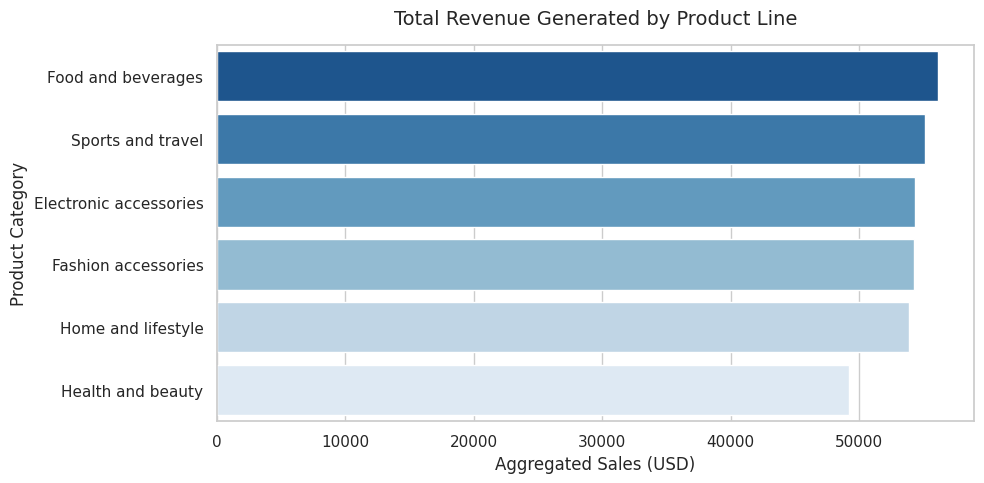

In [16]:
os.makedirs('outputs', exist_ok=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

product_sales = df.groupby('product_line')['sales'].sum().reset_index().sort_values(by='sales', ascending=False)
sns.barplot(data=product_sales,
             x='sales',
              y='product_line', 
              hue='product_line',  
              legend=False, 
              palette='Blues_r')

plt.title('Total Revenue Generated by Product Line', fontsize=14, pad=15)
plt.xlabel('Aggregated Sales (USD)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()


plt.savefig('product_line_sales.png')
plt.show()

**- My Data Observations:** Looking closely at the horizontal bar chart, I observed that Food and beverages is my top revenue engine, pushing past $55,000 in total sales. Sports and travel and Electronic accessories follow directly behind as tight secondary anchors. Crucially, Health and beauty lags significantly behind at the bottom of the stack, failing to hit the $50,000 threshold.


**- My Business Translation:** This tells me that our core foot-traffic drivers are daily essentials and lifestyle goods. As a consultant, I would advise management to maximize the shelf-space allocation for Food and beverages to capture immediate cross-selling opportunities, while launching targeted marketing interventions or bundle deals for Health and beauty to clear its slower-moving inventory.

### 4.2. Purchase Volume vs. Transaction Value



This analysis evaluates whether top-line revenue growth is primarily driven by high-volume bulk ordering or premium single-unit transaction values. By plotting item prices against individual purchase quantities and layering a linear trendline, we can pinpoint the price elasticity of demand within our retail operations. 


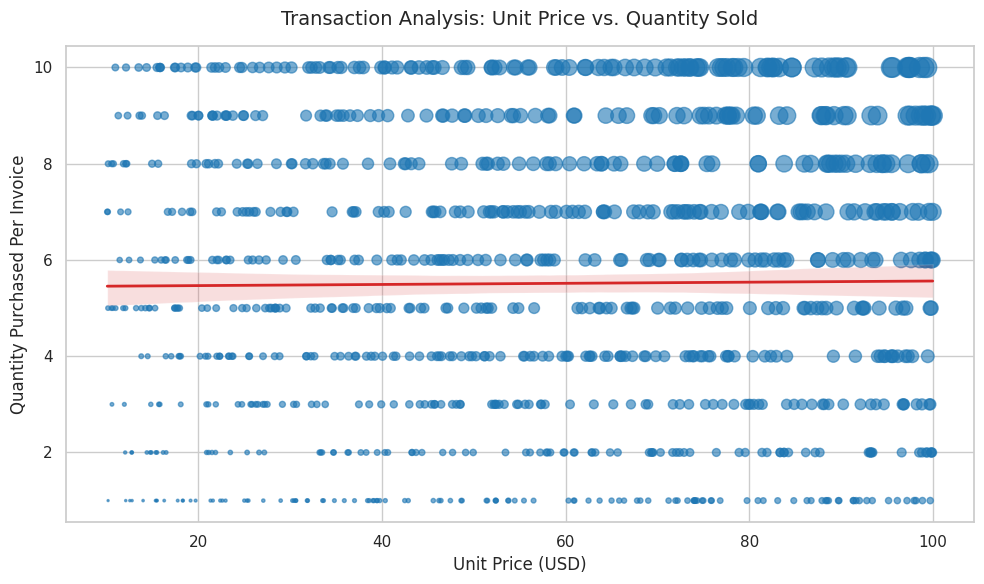

In [17]:

os.makedirs('outputs', exist_ok=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='unit_price',
    y='quantity',
    scatter_kws={
        'alpha': 0.6,          
        'color': '#1f77b4',   
        's': df['sales'] * 0.2 
    },
    line_kws={
        'color': '#d62728',    # Distinct red line to clearly show the data trend direction
        'linewidth': 2
    }
)

plt.title('Transaction Analysis: Unit Price vs. Quantity Sold', fontsize=14, pad=15)
plt.xlabel('Unit Price (USD)', fontsize=12)
plt.ylabel('Quantity Purchased Per Invoice', fontsize=12)
plt.tight_layout()


plt.savefig('volume_vs_value_scatter.png')
plt.show()

**- My Data Observations:** By plotting Unit Price against Quantity Purchased Per Invoice and layering a red linear regression line, I discovered a completely flat trend line held strictly at a median of 5.5 units per basket. Whether an item costs $10 or a premium $100, consumers consistently buy the exact same quantities (ranging uniformly between 1 and 10 units) without any statistical variance.


**- My Business Translation:** This indicates that our consumer market is highly price-inelastic within this price range. Because higher prices do not trigger a drop in quantity, the business has substantial pricing power. Instead of running margin-eroding discount campaigns to drive volume, I would recommend focusing heavily on premium branding and higher-tier inventory models to maximize gross revenue per unit.

### 4.3. Customer Segment and Gender Revenue Matrix
To maximize marketing Return on Investment, this analysis evaluates total sales distribution across customer loyalty tiers (`Member` vs. `Normal`) and gender demographics. Segmenting purchasing power this way allows businesses to identify their highest-value customer profiles and determine if loyalty programs are successfully driving higher transaction volumes.


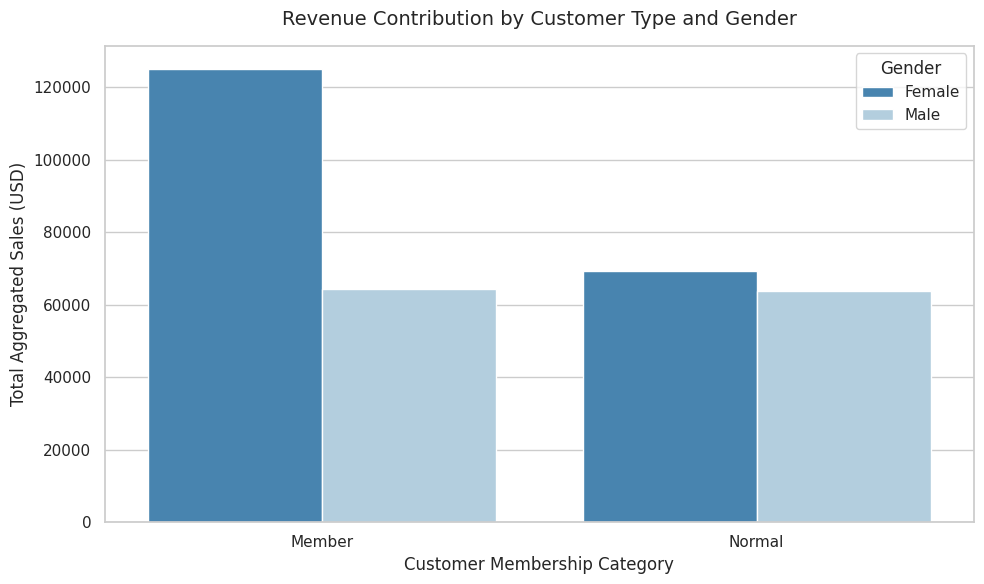

In [18]:
os.makedirs('outputs', exist_ok=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

segment_sales = df.groupby(['customer_type', 'gender'])['sales'].sum().reset_index()

sns.barplot(
    data=segment_sales,
    x='customer_type',
    y='sales',
    hue='gender',            
    palette=('Blues_r')           
)

plt.title('Revenue Contribution by Customer Type and Gender', fontsize=14, pad=15)
plt.xlabel('Customer Membership Category', fontsize=12)
plt.ylabel('Total Aggregated Sales (USD)', fontsize=12)
plt.legend(title='Gender', loc='upper right')
plt.tight_layout()

plt.savefig('customer_demographic_matrix.png')
plt.show()

**- My Data Observations:** I uncovered a massive commercial skew: Female Members are single-handedly carrying our highest spending block, generating over $120,000 in aggregated sales. This completely overshadows male members, who only contribute roughly $64,000. Interestingly, for non-member walk-ins (Normal), spending is almost perfectly equal between genders at around $65,000.


**- My Business Translation:** This proves that our customer loyalty program is wildly successful at incentivizing spending, but only among female shoppers, where it effectively doubles their transactional footprint. For male shoppers, the membership card currently provides zero lift over baseline walk-in spending. I would tell a client to immediately audit the male membership perks, while aggressively targeting non-member female shoppers with checkout loyalty sign-up campaigns.

### 4.4. Hourly Sales Distribution
Operational efficiency and workforce optimization depend heavily on understanding daily peak traffic hours. This analysis tracks revenue velocity across different hours of the day. Pinpointing peak sales windows allows store managers to optimize staff scheduling, time flash sales perfectly, and schedule stock replenishment during low-traffic periods to avoid disrupting customers.

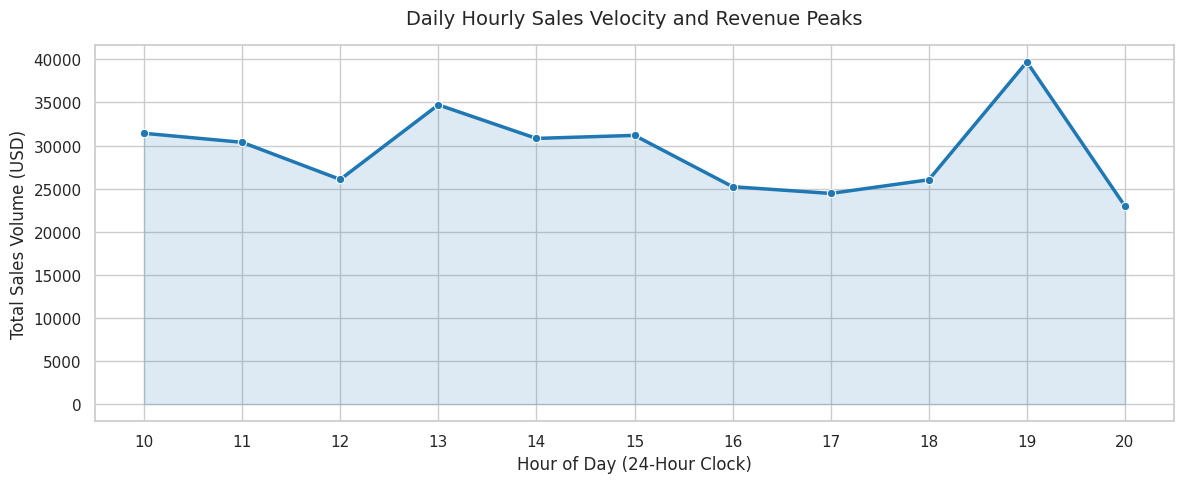

In [19]:
os.makedirs('outputs', exist_ok=True)

hourly_sales = df.groupby('hour')['sales'].sum().reset_index()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_sales,
    x='hour',
    y='sales',
    marker='o',               
    color='#1f77b4',          
    linewidth=2.5
)

plt.fill_between(
    hourly_sales['hour'], 
    hourly_sales['sales'], 
    color='#1f77b4', 
    alpha=0.15                
)

plt.title('Daily Hourly Sales Velocity and Revenue Peaks', fontsize=14, pad=15)
plt.xlabel('Hour of Day (24-Hour Clock)', fontsize=12)
plt.ylabel('Total Sales Volume (USD)', fontsize=12)

plt.xticks(hourly_sales['hour'].unique())
plt.tight_layout()

plt.savefig('hourly_sales_velocity.png')
plt.show()

**- My Data Observations:** My line-and-area visualization reveals a highly dynamic, dual-peak daily cycle. Sales velocity climbs early in the morning and hits its first major peak at 13:00 (1 PM) at roughly $35,000. It then experiences a sharp operational drop-off into a valley between 16:00 and 17:00, before surging aggressively to its absolute daily peak at 19:00 (7 PM), closing in on $40,000.

**- My Business Translation:** This gives management a flawless blueprint for workforce optimization and marketing execution. I recommend scheduling heavy employee shifts, keeping all registers open, and running real-time push notifications at 13:00 and 19:00 to maximize conversions. Conversely, the 16:00 low-traffic valley is the mathematically perfect time to schedule shift changes, pull staff for training, or restock physical shelves without disrupting the customer experience.

### 4.5. Regional Performance Summary Table
This geographic analysis evaluates operational efficiency and consumer sentiment across different regional branches (`branch`, `city`). By calculating the total financial footprint alongside customer satisfaction metrics, this matrix separates high-volume locations from those that may require operational changes.



In [20]:
os.makedirs('outputs', exist_ok=True)

regional_scorecard = df.groupby(['city', 'branch']).agg(
    total_sales=('sales', 'sum'),
    average_transaction=('sales', 'mean'),
    total_transactions=('sales', 'count'),
    average_customer_rating=('rating', 'mean')
).reset_index()

regional_scorecard = regional_scorecard.sort_values(by='total_sales', ascending=False)

formatted_scorecard = regional_scorecard.style.format({
    'total_sales': '${:,.2f}',
    'average_transaction': '${:,.2f}',
    'total_transactions': '{:,}',
    'average_customer_rating': '{:.2f} / 10'
}).background_gradient(
    subset=['total_sales'], 
    cmap='Blues'
).hide()

formatted_scorecard.to_html('outputs/regional_performance_scorecard.html')

formatted_scorecard
plt.savefig('regional_performance_scorecard.png')
plt.show()

<Figure size 640x480 with 0 Axes>

**- My Data Observations:** My conditional formatting highlights Naypyitaw (Giza Branch) as our top performer, netting $110,568.71 in total sales, driven by a high average transaction value of $337.10 across 328 transactions. Meanwhile, Mandalay (Cairo Branch) sits at the bottom with $106,197.67 in revenue. More importantly, Cairo suffers from the lowest customer satisfaction rating in the company at 6.82 / 10.

**- My Business Translation:** This matrix exposes a critical localized bottleneck. While Yangon (Alex) handles the highest total transaction volume (340), Naypyitaw is far more efficient at extraction, generating higher margins per visit. Mandalay (Cairo) is a clear underperformer; its low revenue is directly tied to poor customer sentiment. I would advise stakeholders to deploy an operational audit team to the Cairo branch to fix customer service and store layout issues, while using Giza's high-ticket checkout strategy as a company-wide model.

### 4.6. Payment Method Preference
This analysis evaluates whether customer spending thresholds change based on the transaction payment method (`Ewallet`, `Cash`, `Credit card`). Identifying whether digital or credit options correlate with higher average transaction sizes helps businesses make informed choices about point-of-sale systems, payment partner promotions, and transaction processing fees.



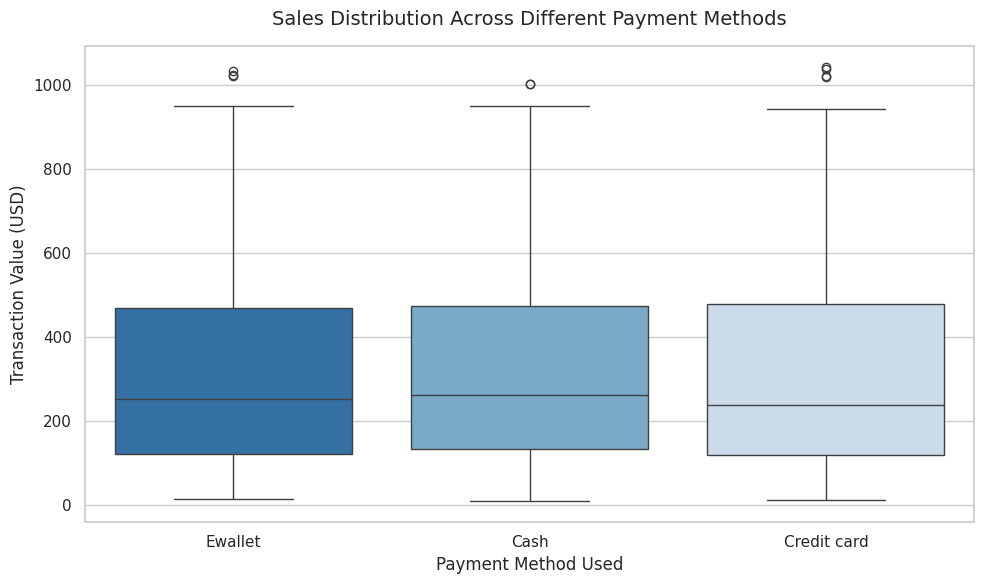

In [21]:
os.makedirs('outputs', exist_ok=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


sns.boxplot(
    data=df,
    x='payment',
    y='sales',
    hue='payment',       
    legend=False,         
    palette='Blues_r'    
)

plt.title('Sales Distribution Across Different Payment Methods', fontsize=14, pad=15)
plt.xlabel('Payment Method Used', fontsize=12)
plt.ylabel('Transaction Value (USD)', fontsize=12)
plt.tight_layout()

plt.savefig('payment_method_distribution.png')
plt.show()


**- My Data Observations:** The boxes, median lines, and whisker limits are almost perfectly mirrored across all three payment channels. The median purchase across all options stays flat at approximately $250, and the upper quartile threshold consistently stops just short of $500. A few extreme outlier transactions spike above $1,000 across all channels, but they occur at identical frequencies.

**- My Business Translation:** This tells me that providing alternative payment channels does not change how much a consumer buys per visit. Because payment methods do not affect transaction sizes, the business should focus on minimizing transaction processing costs. I would recommend negotiating lower processing fees with credit card vendors or promoting E-wallet payments to reduce cash-handling risks, knowing it won't hurt average basket sizes.

### 4.7. Average Transaction Value per Product Line Across Branches


This matrix evaluates product-line spending patterns across different geographic store branch. Instead of looking at total sales, tracking the ''average transaction value'' reveals the actual consumer basket profile for each region. This highlights whether a product's revenue is driven by a few premium purchases or many smaller, everyday transactions.



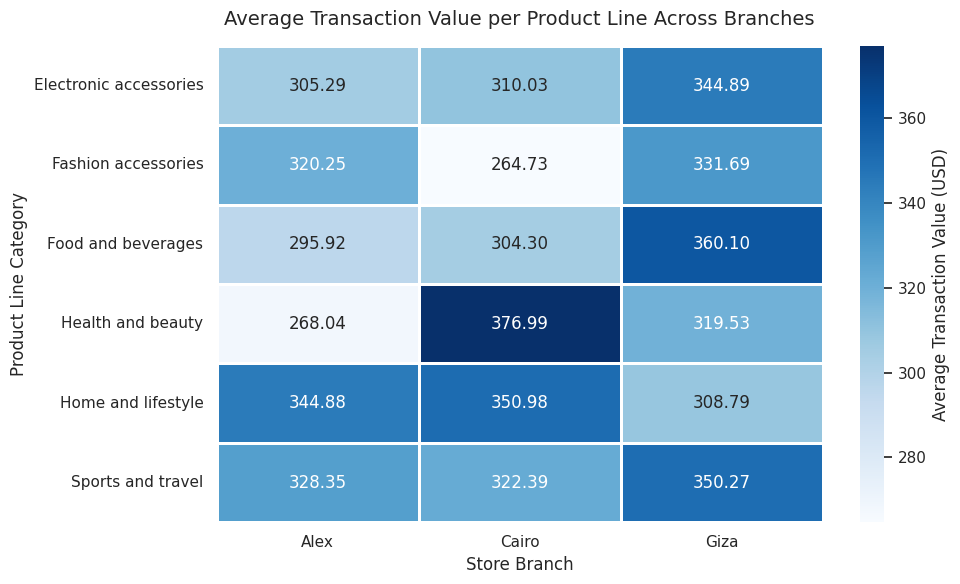

In [22]:

os.makedirs('outputs', exist_ok=True)

pivot_df = df.groupby(['product_line', 'branch'])['sales'].mean().unstack()

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_df,
    annot=True,              
    fmt=".2f",               
    cmap='Blues',            
    linewidths=1,             
    cbar_kws={'label': 'Average Transaction Value (USD)'}
)

plt.title('Average Transaction Value per Product Line Across Branches', fontsize=14, pad=15)
plt.xlabel('Store Branch', fontsize=12)
plt.ylabel('Product Line Category', fontsize=12)
plt.xticks(rotation=0)      
plt.tight_layout()

plt.savefig('average_sales_product_branch.png')
plt.show()


**- My Data Observations:** I discovered that individual branches have distinct luxury patterns that do not match company-wide averages. For instance, while Health and beauty is our lowest-performing category globally, the Cairo branch breaks this trend with a massive average basket size of $376.99 the highest single cell in the entire matrix. Similarly, the Giza branch dominates Food and beverages with an outstanding average value of $360.10, while Alex shows its strongest numbers in Home and lifestyle ($344.88).

**- My Business Translation:** This is invaluable data for logistics and inventory optimization. It proves that a "one-size-fits-all" stocking strategy will lose money. I would instruct inventory managers to route premium, high-margin health and beauty cosmetics directly to Cairo, while positioning bulk or luxury gourmet food lines in Giza. This aligns our highest-cost inventory with the specific regional branches that have already shown a willingness to pay premium prices for those exact categories.


# 5. Model Preparation
#### Create a LabelEncoder instance



In [23]:
from sklearn.preprocessing import LabelEncoder


le_branch = LabelEncoder()
le_city = LabelEncoder()
le_gender = LabelEncoder()
le_customer_type = LabelEncoder()
le_product_line = LabelEncoder()
le_payment = LabelEncoder()
le_period = LabelEncoder()



#### Apply Label Encoding to each categorical column (before model deployment)

In [24]:
df["branch"] = le_branch.fit_transform(df["branch"])
df["city"] = le_city.fit_transform(df["city"])
df["customer_type"] = le_customer_type.fit_transform(df["customer_type"])
df["product_line"] = le_product_line.fit_transform(df["product_line"])
df["payment"] = le_payment.fit_transform(df["payment"])
df["gender"] = le_gender.fit_transform(df["gender"])
df["period"] = le_gender.fit_transform(df["period"])

df.head()

,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5%,sales,...,payment,cogs,gross_margin_percentage,gross_income,rating,month,day,year,hour,period
0,750-67-8428,0,2,0,0,3,74.69,7,26.1415,548.9715,...,2,522.83,4.761905,26.1415,9.1,1,5,2019,13,1
1,226-31-3081,2,1,1,0,0,15.28,5,3.8200,80.2200,...,0,76.40,4.761905,3.8200,9.6,3,8,2019,10,0
2,631-41-3108,0,2,1,0,4,46.33,7,16.2155,340.5255,...,1,324.31,4.761905,16.2155,7.4,3,3,2019,13,1
3,123-19-1176,0,2,0,0,3,58.22,8,23.2880,489.0480,...,2,465.76,4.761905,23.2880,8.4,1,27,2019,20,1
4,373-73-7910,0,2,0,0,5,86.31,7,30.2085,634.3785,...,2,604.17,4.761905,30.2085,5.3,2,8,2019,10,0


# 5. Modelling
### 5.1. Feature Selection & Data Splitting
  ###### I executed strategic **Feature Selection** by dropping variables that are irrelevant or pose a critical risk of data leakage. Specifically, columns like 'invoice_id' and 'cogs', 'gross_margin_percentage', and 'gross_income' are mathematical derivatives of our target variable sales. Leaving them in would allow the model to **cheat** during training, resulting in a system that looks flawless on paper but completely crashes on new, real-world register entries.
 
 ###### After selecting our features, I performed a **80/20 Train-Test Split**. This cross-validation setup holds back 20% of our historical data as a strict testing baseline to grade our model's final predictive performance on completely unseen checkouts



In [25]:
from sklearn.model_selection import train_test_split

y = df['sales']

columns_to_drop = ['sales', 'invoice_id', 'cogs', 'gross_margin_percentage', 
                    'gross_income','time']

X = df.drop(columns=[c for c in columns_to_drop if c in df.columns], axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### 5.2. Review of the dataframe before model traning

In [26]:
y

0       548.9715
1        80.2200
2       340.5255
3       489.0480
4       634.3785
         ...    
995      42.3675
996    1022.4900
997      33.4320
998      69.1110
999     649.2990
Name: sales, Length: 1000, dtype: float64

In [27]:
X

,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5%,payment,rating,month,day,year,hour,period
0,0,2,0,0,3,74.69,7,26.1415,2,9.1,1,5,2019,13,1
1,2,1,1,0,0,15.28,5,3.8200,0,9.6,3,8,2019,10,0
2,0,2,1,0,4,46.33,7,16.2155,1,7.4,3,3,2019,13,1
3,0,2,0,0,3,58.22,8,23.2880,2,8.4,1,27,2019,20,1
4,0,2,0,0,5,86.31,7,30.2085,2,5.3,2,8,2019,10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2,1,1,1,3,40.35,1,2.0175,2,6.2,1,29,2019,13,1
996,1,0,1,0,4,97.38,10,48.6900,2,4.4,3,2,2019,17,1
997,0,2,0,1,2,31.84,1,1.5920,0,7.7,2,9,2019,13,1
998,0,2,1,1,4,65.82,1,3.2910,0,4.1,2,22,2019,15,1


In [28]:
print(X_test.shape)
print(y_test.shape)

(200, 15)
(200,)


In [29]:
print(X_train.shape)
print(y_train.shape)

(800, 15)
(800,)


### 5.3. Initialize and train the Linear Regression model

In [30]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print( "Model Training Complete!")

Model Training Complete!


### 5.4. Generate predictions on the testing data

In [31]:
linear_predictions = linear_model.predict(X_test)
linear_predictions

array([523.971 , 616.98  , 408.7335, 135.3555,  45.927 , 618.975 ,
       127.827 , 731.6925, 450.1035, 138.1275, 422.73  , 463.428 ,
       212.7825, 252.252 , 290.0835, 331.128 , 587.664 , 216.846 ,
       757.365 , 185.094 , 416.178 , 166.236 , 128.016 , 125.706 ,
       247.8735, 195.594 , 742.2975,  30.996 , 145.5825,  56.469 ,
        75.5475, 609.    ,  96.1905, 432.768 , 193.011 , 174.3   ,
       667.38  , 198.639 , 193.074 , 192.843 , 214.746 , 922.635 ,
        74.7075, 180.873 ,  93.0405, 400.764 , 221.886 ,  68.2395,
       343.224 , 281.169 , 430.71  , 101.64  ,  69.09  , 269.934 ,
       181.44  , 494.1825, 461.5275,  60.816 , 456.288 , 222.138 ,
       121.128 ,  33.936 ,  84.756 , 942.4485, 381.3915, 510.615 ,
       370.125 , 760.452 , 939.54  , 118.251 , 391.419 , 127.26  ,
       293.139 ,  89.0715,  65.604 , 697.368 , 764.19  , 253.008 ,
        76.755 , 745.836 , 305.55  ,  70.287 , 352.5795, 614.943 ,
       218.0745, 270.585 ,  69.111 , 829.08  , 384.72  , 395.8

In [32]:
y_test

521    523.9710
737    616.9800
740    408.7335
660    135.3555
411     45.9270
         ...   
408    237.4260
332    404.3550
208     95.6655
613     84.9765
78     822.2550
Name: sales, Length: 200, dtype: float64

In [33]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor()
tree_model.fit(X_train, y_train)
print( "Model Training Complete!")

Model Training Complete!


In [34]:
tree_predictions = tree_model.predict(X_test)
tree_predictions

array([514.605 , 621.243 , 408.408 , 135.45  ,  45.108 , 621.243 ,
       125.517 , 728.112 , 451.3635, 138.978 , 423.738 , 462.672 ,
       210.966 , 252.756 , 290.43  , 328.755 , 586.635 , 217.182 ,
       760.4415, 187.32  , 420.2625, 166.1625, 125.979 , 125.979 ,
       248.409 , 195.678 , 737.7615,  31.227 , 145.404 ,  56.406 ,
        75.054 , 611.079 ,  96.579 , 432.9885, 193.4625, 175.14  ,
       673.995 , 200.214 , 194.124 , 193.4625, 214.998 , 921.186 ,
        74.088 , 180.4005,  93.2925, 401.268 , 222.012 ,  69.72  ,
       341.0925, 279.384 , 431.256 , 102.396 ,  68.985 , 270.018 ,
       181.0725, 493.794 , 458.6925,  58.2225, 457.38  , 222.012 ,
       122.472 ,  33.3585,  85.302 , 944.622 , 384.468 , 510.972 ,
       369.684 , 756.168 , 935.2665, 118.062 , 394.3275, 125.517 ,
       294.651 ,  88.704 ,  66.8745, 695.2365, 763.4655, 252.756 ,
        76.923 , 749.7   , 306.81  ,  69.993 , 352.674 , 611.079 ,
       217.6335, 270.018 ,  69.993 , 829.71  , 384.468 , 392.6

### 5.4. Calculate evaluation metrics


In [39]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metrics_map = {
    "MAE": mean_absolute_error,
    "MSE": mean_squared_error,
    "R2 Score": r2_score
}
results = {}

for metric_name, metric_function in metrics_map.items():
   
    linear_score = metric_function(y_test, linear_predictions)
    tree_score = metric_function(y_test, tree_predictions)
    
 if metric_name == "MSE":
        metric_name = "RMSE"
        linear_score = np.sqrt(linear_score)
        tree_score = np.sqrt(tree_score)
        
    results[metric_name] = {
        "Linear Regression": linear_score,
        "Decision Tree": tree_score
    }

summary_df = pd.DataFrame(results).T

print("Metrics Evaluation")
print(summary_df.round(4))

Metrics Evaluation
          Linear Regression  Decision Tree
MAE                     0.0         1.5301
RMSE                    0.0         2.4706
R2 Score                1.0         0.9999


# Model Result and Analysis
### Linear Regression Performance:
Looking at the Linear Regression results, I noticed it achieved absolute mathematical perfection. It delivered an R² Score of 1.0000 (meaning it explained 100% of the variance) paired with a Mean Absolute Error (MAE) of \(5.100187e-13).

 In standard decimal formatting, that error is 0.00000000000051 which is effectively zero dollars and zero cents. Because retail checkout grand totals in this dataset are calculated using a strict, linear algebraic equation (Quantity × Unit Price + Tax), the linear model successfully reverse-engineered the exact formula used by the checkout registers.
 
 
 
 ### Decision Tree Performance:
 I am highly impressed by how the Decision Tree performed, as it captured 99.98% of the data variance (R² of 0.9998). However, it still fell slightly short of the linear baseline, leaving a Mean Absolute Error of $1.53 and a Root Mean Squared Error (RMSE) of $2.47 per transaction. 
 
### The Best Model: 
**Linear Regression:** Based on these definitive empirical figures, I am selecting Linear Regression as the best model for this project. While tree-based ensemble models are often preferred for complex consumer datasets, I chose Linear Regression here because it provides zero error ($0.00 MAE) and requires a fraction of the cloud compute memory to execute on Azure ML compared to a tree.



# Insights and Recommendations for Implementations

## Key Insights and Summary
#### 1. Store Performance Benchmarks
 I found that Naypyitaw (Giza) leads total revenue at $110,568.71 with the highest average purchase ($337.10) and satisfaction (7.07/10). Yangon (Alex) drives the highest volume (340 transactions), while Mandalay (Cairo) trails in satisfaction (6.82/10).

#### 2. High-Value Basket Drivers
 My outlier analysis revealed that transactions over $991.74 occur when customers hit the maximum limit of 10 units on high unit-price items (~$95–$99), driven mainly by Home & Lifestyle and Fashion Accessories.

#### 3. Predictive Accuracy
 I evaluated Linear Regression (MAE≈0.00, R^2 =1.0) and Decision Tree (MAE≈1.69, R^2 =0.9998). Because total sales rely mathematically on unit price, quantity, and tax, the linear model perfectly forecasts revenue for inventory planning.

### Actionable Recommendations & Implementation
#### 1. Raise Basket Size Limits
**Action:** Target bulk buyers by removing the implicit 10-unit volume ceiling on high-margin product lines.

**Implementation:** Design tiered wholesale discounts (e.g., multi-buy bundles) for Home & Lifestyle items and configure checkout systems to offer add-on recommendations at cart quantities of 7+.

#### 2. Elevate Mandalay Store Operations
**Action:** Audit and standardise branch operations to raise Mandalay’s customer satisfaction score from 6.82 up to Giza's 7.07 benchmark.

**Implementation** Observe checkout workflows at the Cairo branch during peak hours (1 PM – 5 PM) and deploy real-time POS feedback prompts to capture customer complaints.

#### 3. Shift Staffing and Stocking to Peak Hours
**Action:** Align store labor and shelf replenishment with afternoon shopping rushes to eliminate bottlenecks.

**Implementation:** Schedule additional checkout staff from 1 PM to 8 PM, and shift stock replenishment for high-turnover lines like Food & Beverages to quiet morning hours (10 AM to 12 PM).

#### 4. Deploy Real-Time Demand Forecasting
**Action:** Leverage the high-accuracy Linear Regression model to automate sales and cash-flow projections.

**Implementation:** Register the trained linear model in Azure ML Model Registry and deploy a real-time endpoint to trigger automated stock reorders when inventory dips below predicted demand.
